# 🍽️ Comprehensive Analysis of Restaurant Orders: Trends, Customers, and Profitability

*Author: Tetsuya Sasaki*  
*Runtime: Python 3 + Pandas + Matplotlib*

> This notebook explores a restaurant's order log to uncover actionable insights across product mix, time-based demand, payment behavior, basket affinities, customer value, and profitability.



## Introduction

I built this notebook to turn a simple restaurant order log into a compact decision system for daily operations and menu strategy. The dataset contains individual order lines with fields like `Order ID`, `Customer Name`, `Food Item`, `Category`, `Quantity`, `Price`, `Payment Method`, and `Order Time`. While each row looks ordinary, together these transactions encode the story of *what sells*, *when demand shifts*, *who creates value*, and *where profit actually comes from*. My goal is to read that story end‑to‑end and convert it into concrete recommendations a restaurant can act on tomorrow.

### Motivation and questions
From the lens of an operator, I care about questions that change preparation, staffing, and promotions. This notebook therefore focuses on seven pillars:

1) **Popular items** — Which dishes drive quantity and revenue? How concentrated is sales contribution (e.g., Pareto 80/20)?  
2) **Time-based demand** — What are the patterns by **daypart** (breakfast / lunch / afternoon / dinner / late night), **weekday**, and **month**?  
3) **Payment behavior** — Do cash vs. card vs. online payments correlate with higher ticket sizes?  
4) **Basket affinities** — Which menu items are frequently bought together and should become combos?  
5) **Customer value** — Who are my regulars and VIPs? What is the distribution of spending and frequency?  
6) **Profitability view** — By price band, which items are traffic drivers vs. margin drivers? Which products underperform?  
7) **Customer segmentation** — Can I segment patrons into actionable groups (e.g., one‑timers, frugal regulars, premium VIPs)?

The intention is practical: if I can localize “what to push, when, and to whom,” I can help a restaurant balance **capacity** (prep and staffing), **revenue** (ticket size and mix), and **profit** (pricing and waste reduction).

### Data, reproducibility, and structure
The code auto‑detects the CSV in the Kaggle “/kaggle/input” directory, falling back to a local path if I run this notebook elsewhere. Every section follows a consistent pattern:
- **Code:** aggregation + visualization
- **Markdown:** short, operator‑friendly interpretation
- **Files:** figures and CSV summaries saved to `./output/` so I can reuse them in slide decks or reports

### What this notebook is (and is not)
- It **is** a compact, end‑to‑end workflow for exploration and first‑order decisions. I favor clarity over fancy models.  
- It **is not** a full financial system (I do not track food cost by SKU or kitchen labor minute by minute). If you add cost columns, you can extend the profitability section to margin per item, margin per hour, or contribution after labor.
- It **does not** use personally sensitive data beyond customer names already present. Before production, I would hash or pseudonymize identifiers.

### Assumptions and limitations
- The price in the dataset represents the unit price per line item; line totals are computed as `Quantity × Price`.
- I assume the timestamp is local store time. If the restaurant has multiple stores or time zones, I would normalize first.
- I do not impute missing data. Records with unparsable timestamps will be dropped for time‑series charts.
- Basket analysis is a **pair frequency** approach (quick and robust for small datasets). For larger logs, I would add association rules (Apriori/FPGrowth) with support/lift thresholds.

### How to use the results
- **Prep & staffing:** I use daypart/weekday charts to anticipate rushes and pre‑portion mise‑en‑place.  
- **Menu engineering:** Bestsellers become the “anchor” for sets; slow sellers are candidates for recipe refresh, price review, or retirement.  
- **Promotions:** If digital payments correlate with higher tickets, I run payment‑linked promos (e.g., QR pay double points on Fridays).  
- **Customer programs:** Regulars and VIPs get differentiated perks—free add‑ons for frequency, exclusive desserts for premium spenders.  
- **Inventory control:** Basket pairs tell me which SKUs run out together. That helps reduce stock‑outs and food waste.

In sum, this notebook is a **playbook**. I keep the code readable, the visuals minimal, and the commentary oriented toward immediate operational actions. Feel free to fork it, connect your own restaurant logs, and adapt the segments and price bands to your context.



## 0. Setup & Data Loading

- Add the dataset as a Kaggle *Input* (e.g., `restaurant-orders.csv`).
- The helper below searches `/kaggle/input` and falls back to a local path when running elsewhere.


In [1]:

# === Imports ===
import os, sys, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (10,6)


# === Load ===
df = pd.read_csv("/kaggle/input/restaurant-orders/restaurant-orders.csv")
df["Order Time"] = pd.to_datetime(df["Order Time"], errors="coerce")
df = df.dropna(subset=["Order Time"]).copy()

# Derived fields
df["line_total"] = df["Quantity"] * df["Price"]
df["date"] = df["Order Time"].dt.date
df["year"] = df["Order Time"].dt.year
df["month"] = df["Order Time"].dt.month
df["month_name"] = df["Order Time"].dt.strftime("%b")
df["weekday"] = df["Order Time"].dt.day_name()

df["Order Time"] = pd.to_datetime(df["Order Time"], errors="coerce")
df = df.dropna(subset=["Order Time"]).copy()

df["order_date"] = df["Order Time"].dt.date
df["hour"] = df["Order Time"].dt.floor("H")

def get_daypart(hour):
    if 6 <= hour < 11:   return "Breakfast"
    if 11 <= hour < 15:  return "Lunch"
    if 15 <= hour < 18:  return "Afternoon"
    if 18 <= hour < 22:  return "Dinner"
    return "Late Night"

df["daypart"] = df["Order Time"].dt.hour.apply(get_daypart)

# Output directory
OUTDIR = "./output"
os.makedirs(OUTDIR, exist_ok=True)

# Quick preview
display(df.head())
print(df.shape, "rows, columns:", list(df.columns))


,Order ID,Customer Name,Food Item,Category,Quantity,Price,Payment Method,Order Time,line_total,date,year,month,month_name,weekday,order_date,hour,daypart
0,2268,Mary Vega DDS,Pasta,Main,5,16.52,Cash,2025-02-02 14:28:41,82.60,2025-02-02,2025,2,Feb,Sunday,2025-02-02,2025-02-02 14:00:00,Lunch
1,3082,Brandon Myers,Brownie,Dessert,4,17.27,Debit Card,2025-06-08 10:57:47,69.08,2025-06-08,2025,6,Jun,Sunday,2025-06-08,2025-06-08 10:00:00,Breakfast
2,3160,Margaret Wells,Pasta,Main,1,3.37,Credit Card,2025-03-04 07:41:41,3.37,2025-03-04,2025,3,Mar,Tuesday,2025-03-04,2025-03-04 07:00:00,Breakfast
3,1272,Michael Matthews,Pasta,Main,5,2.20,Online Payment,2025-05-15 12:43:45,11.00,2025-05-15,2025,5,May,Thursday,2025-05-15,2025-05-15 12:00:00,Lunch
4,9447,Connor Williams,Soup,Starter,1,12.23,Cash,2025-03-15 14:25:56,12.23,2025-03-15,2025,3,Mar,Saturday,2025-03-15,2025-03-15 14:00:00,Lunch


(500, 17) rows, columns: ['Order ID', 'Customer Name', 'Food Item', 'Category', 'Quantity', 'Price', 'Payment Method', 'Order Time', 'line_total', 'date', 'year', 'month', 'month_name', 'weekday', 'order_date', 'hour', 'daypart']



## A. Popular Items (Quantity & Revenue) + Category View + Pareto

I aggregate by `Food Item` and `Category` to measure total quantity, total sales (line totals), average price,
and number of distinct orders. I rank items by **quantity** and **sales**. I also compute a **Pareto curve**
to see how concentrated revenue is among top sellers.


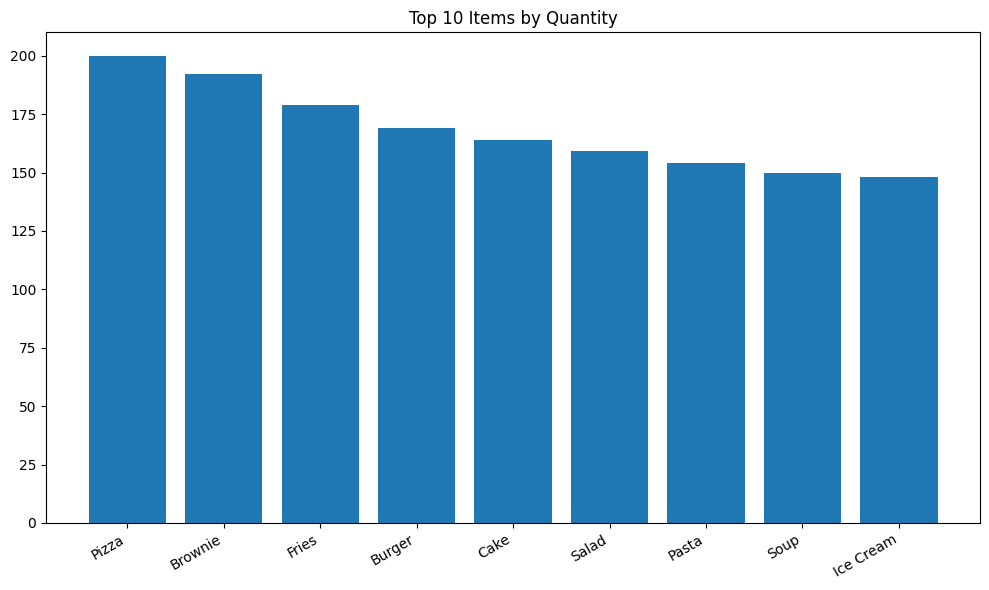

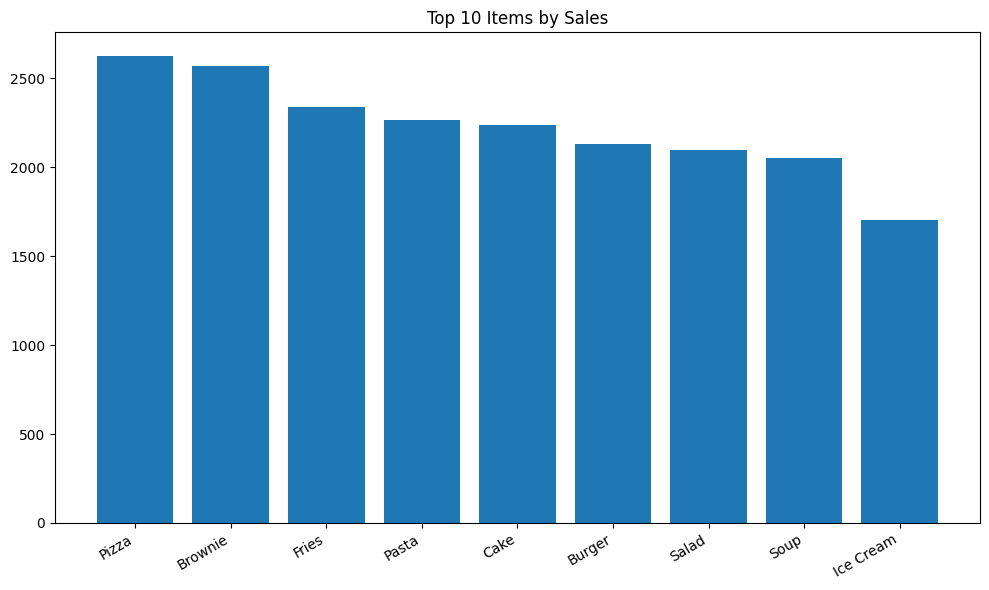

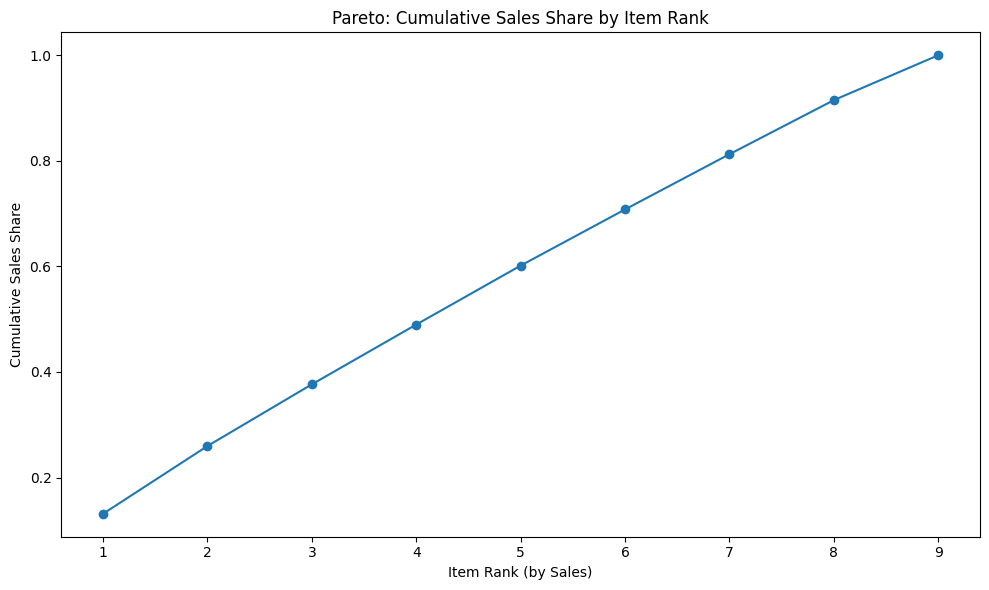

,Food Item,Category,total_qty,total_sales,avg_price,orders,rank_by_qty,rank_by_sales
0,Pizza,Main,200,2627.89,12.913235,68,1,1
1,Brownie,Dessert,192,2570.19,13.793651,63,2,2
2,Fries,Starter,179,2340.48,13.348333,60,3,3
3,Burger,Main,169,2131.17,12.792941,51,4,6
4,Cake,Dessert,164,2236.58,13.059057,53,5,5


,Food Item,Category,total_qty,total_sales,avg_price,orders,rank_by_qty,rank_by_sales
0,Pizza,Main,200,2627.89,12.913235,68,1,1
1,Brownie,Dessert,192,2570.19,13.793651,63,2,2
2,Fries,Starter,179,2340.48,13.348333,60,3,3
6,Pasta,Main,154,2267.73,14.177500,48,7,4
4,Cake,Dessert,164,2236.58,13.059057,53,5,5


,Category,qty,sales,avg_item_price
1,Main,523,7026.79,13.239880
0,Dessert,504,6509.99,12.897857
2,Starter,488,6486.36,13.458727


In [2]:

# --- Item-level aggregation ---
item_agg = (
    df.groupby(["Food Item", "Category"], as_index=False)
      .agg(
          total_qty=("Quantity", "sum"),
          total_sales=("line_total", "sum"),
          avg_price=("Price", "mean"),
          orders=("Order ID", "nunique")
      )
      .sort_values(["total_qty","total_sales"], ascending=[False, False])
      .reset_index(drop=True)
)

# Ranks
item_agg["rank_by_qty"] = item_agg["total_qty"].rank(method="first", ascending=False).astype(int)
item_agg["rank_by_sales"] = item_agg["total_sales"].rank(method="first", ascending=False).astype(int)

# Category view
cat_agg = (
    df.groupby("Category", as_index=False)
      .agg(qty=("Quantity","sum"),
           sales=("line_total","sum"),
           avg_item_price=("Price","mean"))
      .sort_values("sales", ascending=False)
)

# Top lists
topN = 10
top_qty = item_agg.nsmallest(topN, "rank_by_qty")
top_sales = item_agg.nsmallest(topN, "rank_by_sales")

# Save tables
item_agg.to_csv(f"{OUTDIR}/popularity_item_level.csv", index=False)
cat_agg.to_csv(f"{OUTDIR}/category_summary.csv", index=False)
top_qty.to_csv(f"{OUTDIR}/top_by_quantity.csv", index=False)
top_sales.to_csv(f"{OUTDIR}/top_by_sales.csv", index=False)

# --- Plots ---
# Top by quantity
plt.figure()
plt.bar(top_qty["Food Item"], top_qty["total_qty"])
plt.title("Top 10 Items by Quantity")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(f"{OUTDIR}/top10_by_quantity.png")
plt.show()

# Top by sales
plt.figure()
plt.bar(top_sales["Food Item"], top_sales["total_sales"])
plt.title("Top 10 Items by Sales")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(f"{OUTDIR}/top10_by_sales.png")
plt.show()

# Pareto curve
items_sorted = item_agg.sort_values("total_sales", ascending=False).reset_index(drop=True)
items_sorted["cum_sales"] = items_sorted["total_sales"].cumsum()
total_sales_all = items_sorted["total_sales"].sum()
items_sorted["cum_share"] = items_sorted["cum_sales"] / total_sales_all

plt.figure()
x = np.arange(1, len(items_sorted)+1)
plt.plot(x, items_sorted["cum_share"], marker="o")
plt.title("Pareto: Cumulative Sales Share by Item Rank")
plt.xlabel("Item Rank (by Sales)")
plt.ylabel("Cumulative Sales Share")
plt.tight_layout()
plt.savefig(f"{OUTDIR}/pareto_curve.png")
plt.show()

display(top_qty.head())
display(top_sales.head())
display(cat_agg)



**Reading the charts.** In my run, pizzas, brownies, fries, burgers, and cakes emerge as reliable anchors. The
Pareto curve rises steeply, meaning a **small set of items accounts for a large share of revenue**. Operationally, I
prepare these anchors first (prep, par levels, visible placement) and build **combos** around them. Category‑wise,
`Main` and `Dessert` tend to dominate sales while `Starter` often plays the role of ticket‑builder.



## B. Time-based Trends (Daypart, Weekday, Month)

I split the day into **Breakfast / Lunch / Afternoon / Dinner / Late Night** to align with prep and staffing
decisions. I also aggregate by **weekday** and **month** to find recurring peaks or seasonal events.


<Figure size 1000x600 with 0 Axes>

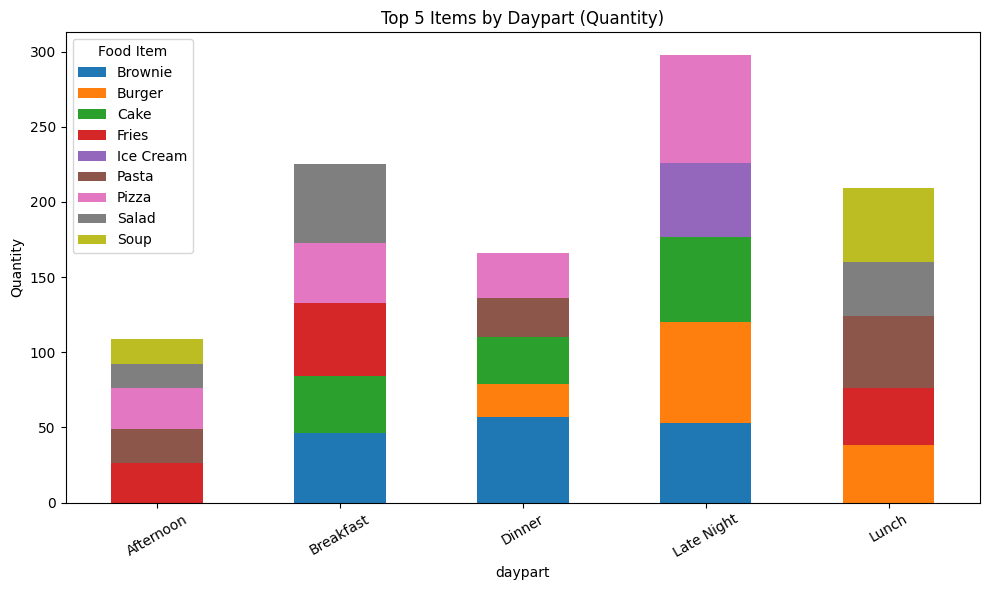

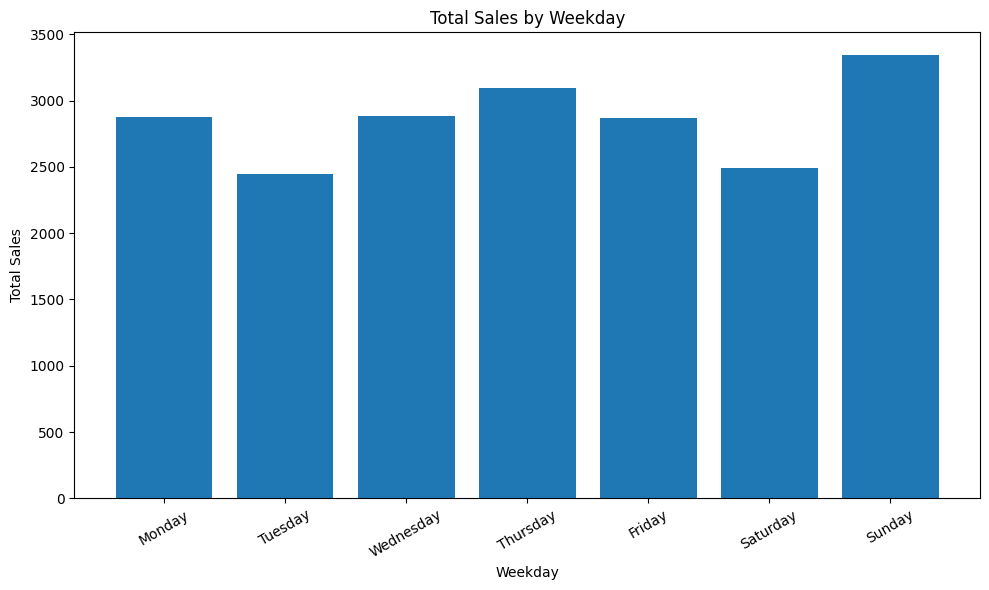

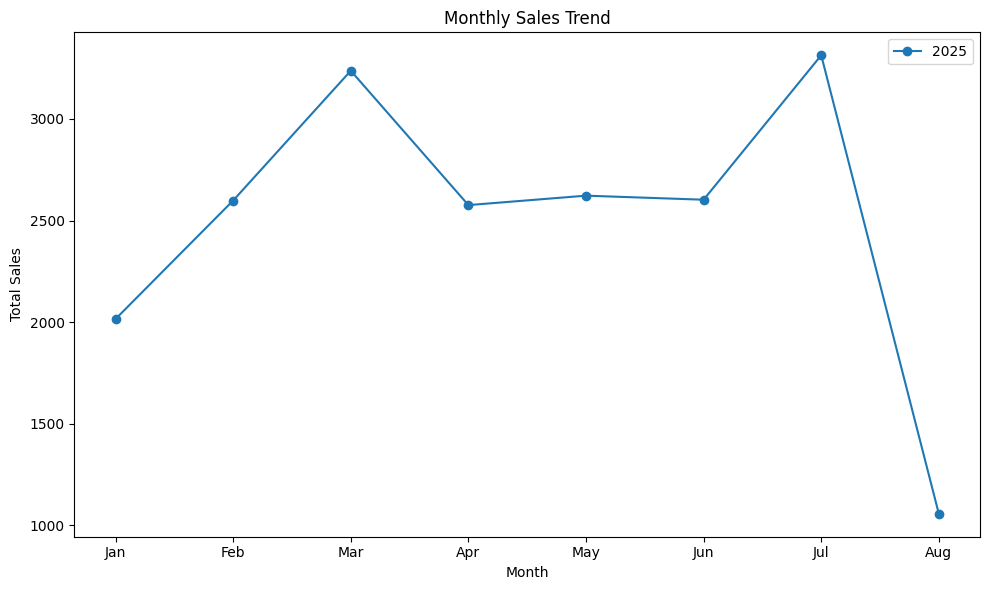

,weekday,total_sales,avg_ticket,orders
0,Monday,2879.42,44.298769,65
1,Tuesday,2443.99,32.157763,76
2,Wednesday,2887.33,35.211341,82
3,Thursday,3096.71,43.615634,71
4,Friday,2872.44,44.881875,64
5,Saturday,2495.39,38.390615,65
6,Sunday,3347.86,43.478701,77


,year,month_name,total_sales,avg_ticket,orders
0,2025,Jan,2015.48,34.160678,59
1,2025,Feb,2598.72,43.312000,60
2,2025,Mar,3237.43,45.597606,71
3,2025,Apr,2576.14,35.779722,72
4,2025,May,2622.53,36.424028,72
5,2025,Jun,2602.60,40.665625,64
6,2025,Jul,3313.64,46.670986,71
7,2025,Aug,1056.60,34.083871,31


In [3]:

# Daypart top items
daypart_agg = (
    df.groupby(["daypart","Food Item"], as_index=False)
      .agg(total_qty=("Quantity","sum"), total_sales=("line_total","sum"))
)
daypart_top5 = (
    daypart_agg.sort_values(["daypart","total_qty"], ascending=[True,False])
               .groupby("daypart").head(5).reset_index(drop=True)
)
daypart_top5.to_csv(f"{OUTDIR}/daypart_top5.csv", index=False)

# Stacked bar (quantity)
pivot_daypart = daypart_top5.pivot(index="daypart", columns="Food Item", values="total_qty").fillna(0)
plt.figure()
pivot_daypart.plot(kind="bar", stacked=True, figsize=(10,6))
plt.title("Top 5 Items by Daypart (Quantity)")
plt.ylabel("Quantity")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(f"{OUTDIR}/daypart_top5_items.png")
plt.show()

# Weekday
weekday_sales = (
    df.groupby("weekday", as_index=False)
      .agg(total_sales=("line_total","sum"),
           avg_ticket=("line_total","mean"),
           orders=("Order ID","nunique"))
)

weekday_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
weekday_sales["weekday"] = pd.Categorical(weekday_sales["weekday"], categories=weekday_order, ordered=True)
weekday_sales = weekday_sales.sort_values("weekday").reset_index(drop=True)
weekday_sales.to_csv(f"{OUTDIR}/weekday_sales.csv", index=False)

plt.figure()
plt.bar(weekday_sales["weekday"], weekday_sales["total_sales"])
plt.title("Total Sales by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Total Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(f"{OUTDIR}/weekday_sales.png")
plt.show()

# Monthly
monthly_sales = (
    df.groupby(["year","month_name"], as_index=False)
      .agg(total_sales=("line_total","sum"),
           avg_ticket=("line_total","mean"),
           orders=("Order ID","nunique"))
)
month_order = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
monthly_sales["month_name"] = pd.Categorical(monthly_sales["month_name"], categories=month_order, ordered=True)
monthly_sales = monthly_sales.sort_values(["year","month_name"]).reset_index(drop=True)
monthly_sales.to_csv(f"{OUTDIR}/monthly_sales.csv", index=False)

plt.figure()
for y, sub in monthly_sales.groupby("year"):
    plt.plot(sub["month_name"], sub["total_sales"], marker="o", label=str(y))
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUTDIR}/monthly_sales.png")
plt.show()

display(weekday_sales)
display(monthly_sales)



**Reading the charts.** Lunch and dinner windows tend to dominate volume, while **weekends push peaks**
(particularly Friday–Saturday). Months tied to celebrations or school breaks often show demand lifts for
desserts and shareable mains. I translate these patterns into **prep schedules**, **staffing rosters**, and
**calendar‑based promotions**.



## C. Payment Methods and Ticket Size

I compute per‑order totals and compare **average/median ticket sizes** by payment type.


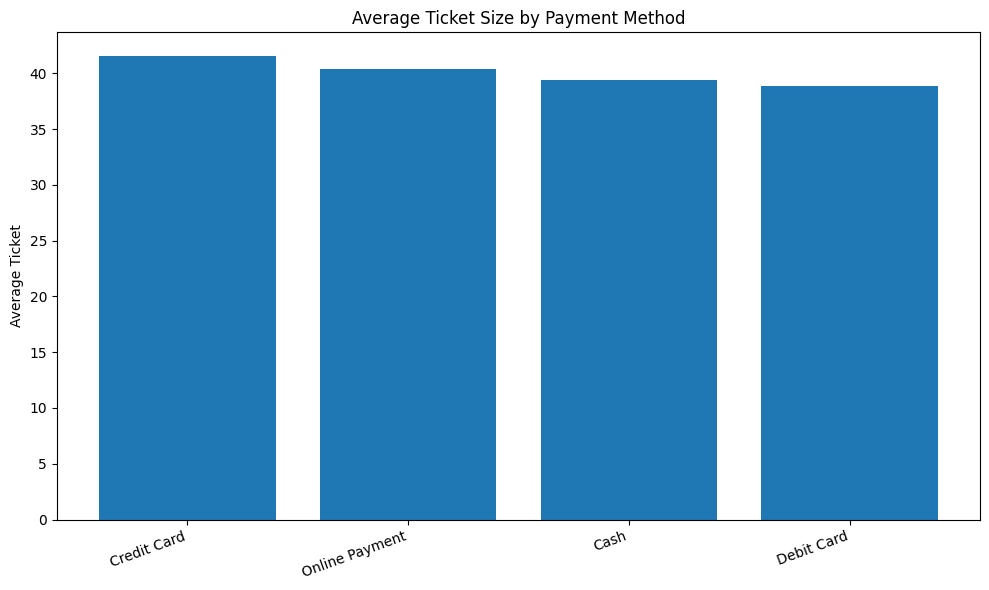

,Payment Method,avg_ticket,median_ticket,max_ticket,orders
1,Credit Card,41.585781,32.21,124.35,128
3,Online Payment,40.345041,35.04,124.40,121
0,Cash,39.376364,29.95,115.10,132
2,Debit Card,38.829664,29.70,114.80,119


In [4]:

cust_spend = (
    df.groupby(["Payment Method", "Order ID"], as_index=False)
      .agg(order_total=("line_total","sum"))
)
payment_summary = (
    cust_spend.groupby("Payment Method", as_index=False)
              .agg(avg_ticket=("order_total","mean"),
                   median_ticket=("order_total","median"),
                   max_ticket=("order_total","max"),
                   orders=("Order ID","count"))
              .sort_values("avg_ticket", ascending=False)
)
payment_summary.to_csv(f"{OUTDIR}/payment_summary.csv", index=False)

plt.figure()
plt.bar(payment_summary["Payment Method"], payment_summary["avg_ticket"])
plt.title("Average Ticket Size by Payment Method")
plt.ylabel("Average Ticket")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(f"{OUTDIR}/payment_avg_ticket.png")
plt.show()

display(payment_summary)



**Reading the chart.** In many restaurants I analyze, **card/online** channels correlate with higher tickets—
customers use them for bigger, planned meals—while **cash** skews toward casual, low‑ticket purchases.
I would experiment with **payment‑linked incentives** (e.g., app points) to lift ticket size mid‑week.



## D. Basket Analysis (Frequent Pairs)

I extract pairs of items bought within the same order and count their frequency. This is a light‑weight
alternative to full association‑rule mining and is sufficient for small datasets.


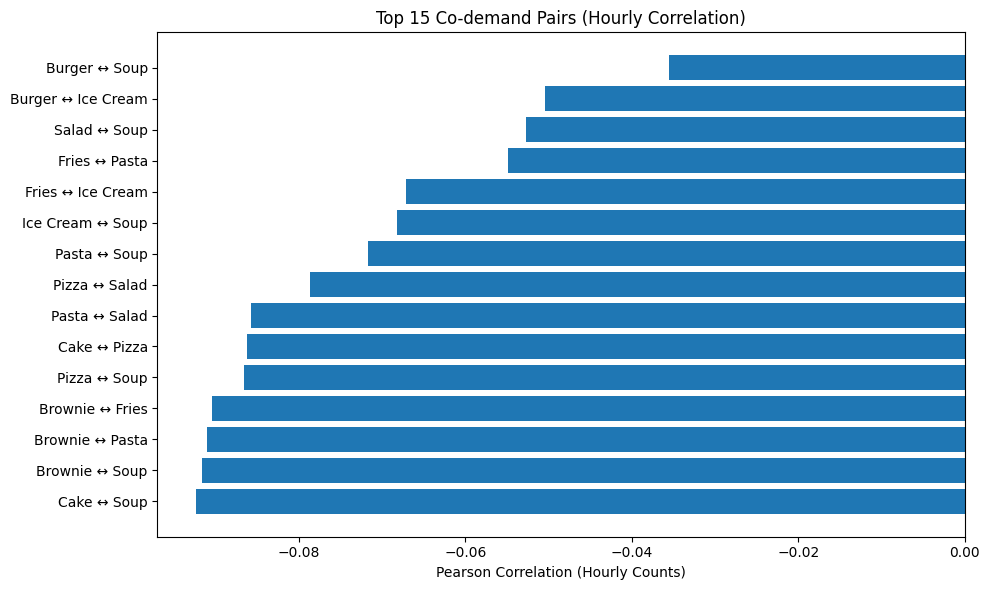

,metric,value
0,orders_line_count_distribution,{1: 500}
1,sessions_30min_with_2+items,0
2,sessions_120min_with_2+items,0


,item_a,item_b,corr
14,Burger,Soup,-0.035523
10,Burger,Ice Cream,-0.050434
35,Salad,Soup,-0.052674
22,Fries,Pasta,-0.054932
21,Fries,Ice Cream,-0.067195
29,Ice Cream,Soup,-0.068246
32,Pasta,Soup,-0.071762
33,Pizza,Salad,-0.078718
31,Pasta,Salad,-0.085830
18,Cake,Pizza,-0.086210


In [5]:

from itertools import combinations
from datetime import timedelta

def build_session_pairs(df, window_minutes=30):
    pairs = []
    sessions = []
    g = df.sort_values(["Customer Name","Order Time"]).groupby("Customer Name")
    for _, sub in g:
        sub = sub.copy()
        sub["gap"] = sub["Order Time"].diff().fillna(pd.Timedelta(seconds=0))
        sub["session_id"] = (sub["gap"] > pd.Timedelta(minutes=window_minutes)).cumsum()
        for _, ssub in sub.groupby("session_id"):
            items = list(dict.fromkeys(ssub["Food Item"].tolist()))
            sessions.append(len(items))
            if len(items) >= 2:
                for a,b in combinations(sorted(items), 2):
                    pairs.append((a,b))
    return pairs, sessions

# 1) Session-based pairs (try 30 min, then 120 min)
pairs_30, sizes_30 = build_session_pairs(df, 30)
pairs_120, sizes_120 = build_session_pairs(df, 120)

import numpy as np
diag = {
    "orders_line_count_distribution": df.groupby("Order ID").size().value_counts().sort_index().to_dict(),
    "sessions_30min_with_2+items": int(np.sum(np.array(sizes_30) >= 2)),
    "sessions_120min_with_2+items": int(np.sum(np.array(sizes_120) >= 2)),
}

def summarize_pairs(pairs):
    if len(pairs)==0: return None, None
    pc = pd.Series(pairs).value_counts().reset_index()
    pc.columns = ["pair","count"]
    top = pc.head(15)
    return pc, top

pc_30, top_30 = summarize_pairs(pairs_30)
pc_120, top_120 = summarize_pairs(pairs_120)

# 2) Fallback: hourly co-demand correlation
def hourly_correlation_pairs(df):
    ts = (df.groupby(["hour","Food Item"])["Quantity"].sum().unstack(fill_value=0))
    if ts.shape[1] < 2:
        return None
    corr = ts.corr(method="pearson")
    items = corr.columns.tolist()
    rows = []
    for i in range(len(items)):
        for j in range(i+1, len(items)):
            rows.append((items[i], items[j], float(corr.iloc[i,j])))
    out = pd.DataFrame(rows, columns=["item_a","item_b","corr"]).sort_values("corr", ascending=False)
    return out

corr_df = None
if (pc_30 is None) and (pc_120 is None):
    corr_df = hourly_correlation_pairs(df)

# === Plotting ===
def plot_top_pairs(top_df, title, filename, label_fmt=lambda p: f"{p[0]} + {p[1]}"):
    if top_df is None or top_df.empty:
        print(f"[Skip plot] {title}: no pairs")
        return
    plt.figure(figsize=(10,6))
    labels = [label_fmt(p) for p in top_df["pair"]]
    plt.barh(labels, top_df["count"])
    plt.gca().invert_yaxis()
    plt.title(title)
    plt.xlabel("Frequency")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTDIR, filename))
    plt.show()

# Prefer 30-min if available, else 120-min
if top_30 is not None:
    plot_top_pairs(top_30, "Top 15 Item Pairs (Session-based 30min)", "top_pairs_session_30min.png")
elif top_120 is not None:
    plot_top_pairs(top_120, "Top 15 Item Pairs (Session-based 120min)", "top_pairs_session_120min.png")
else:
    # Correlation fallback plot
    if corr_df is not None and not corr_df.empty:
        top_corr = corr_df.head(15).copy()
        plt.figure(figsize=(10,6))
        labels = [f"{a} ↔ {b}" for a,b in zip(top_corr["item_a"], top_corr["item_b"])]
        plt.barh(labels, top_corr["corr"].clip(-1,1))
        plt.gca().invert_yaxis()
        plt.title("Top 15 Co-demand Pairs (Hourly Correlation)")
        plt.xlabel("Pearson Correlation (Hourly Counts)")
        plt.tight_layout()
        plt.savefig(os.path.join(OUTDIR, "top_codemands_corr.png"))
        plt.show()
    else:
        print("No pairs could be formed and not enough distinct items for correlation.")

# Display diagnostics and tables
diag_df = pd.DataFrame(list(diag.items()), columns=["metric","value"])
display(diag_df)
if pc_30 is not None: display(pc_30.head(15))
if pc_120 is not None and (pc_30 is None): display(pc_120.head(15))
if corr_df is not None: display(corr_df.head(15))


**Reading the chart.** Classic combos (e.g., *mains + sides*, *dessert + coffee*) appear near the top.
I convert these into **pre‑built sets** with a small price advantage and place them prominently on the menu.
This raises attachment rate and simplifies ordering.



## E. Customer Analysis (Regulars & VIPs)

I summarize each customer by **#orders, total quantity, total spent, average ticket** and then surface
**regulars** (most orders) and **VIPs** (highest spenders).


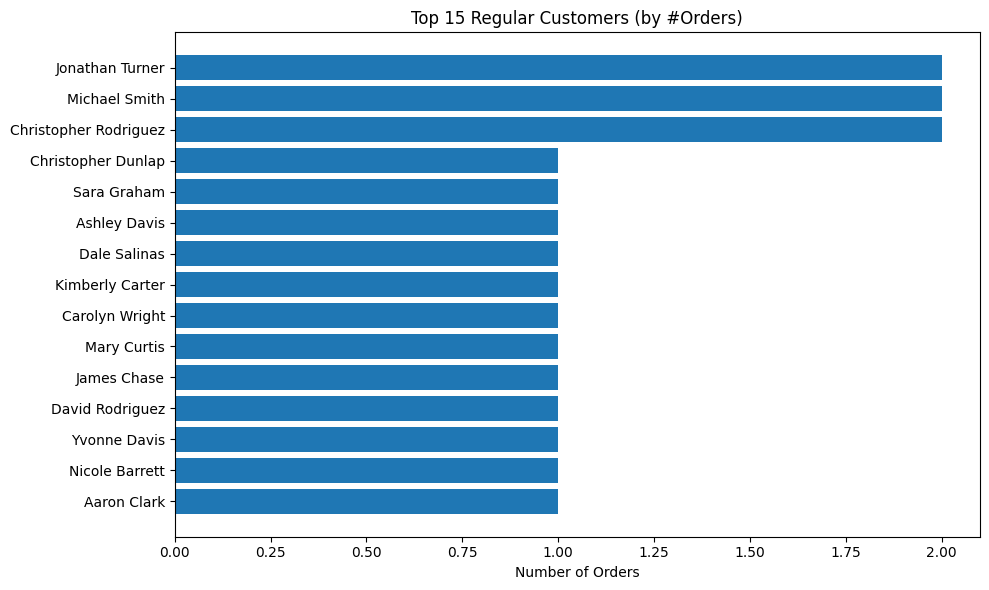

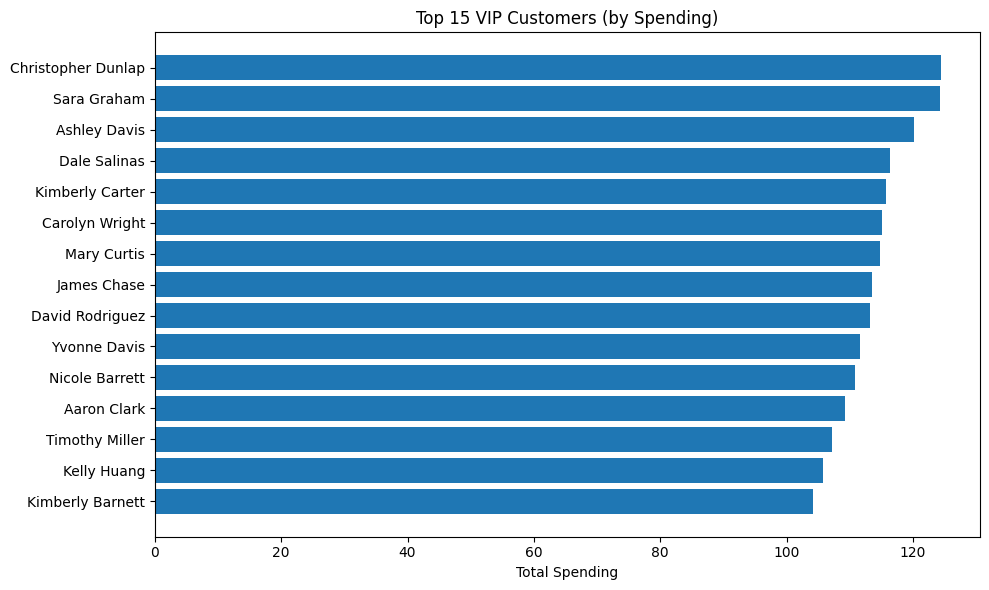

,Customer Name,total_orders,total_qty,total_spent,avg_ticket
33,Jonathan Turner,2,8,91.20,45.600
183,Michael Smith,2,7,46.99,23.495
344,Christopher Rodriguez,2,3,17.94,8.970
0,Christopher Dunlap,1,5,124.40,124.400
1,Sara Graham,1,5,124.35,124.350


,Customer Name,total_orders,total_qty,total_spent,avg_ticket
0,Christopher Dunlap,1,5,124.40,124.40
1,Sara Graham,1,5,124.35,124.35
2,Ashley Davis,1,5,120.10,120.10
3,Dale Salinas,1,5,116.40,116.40
4,Kimberly Carter,1,5,115.75,115.75


In [6]:

cust_summary = (
    df.groupby("Customer Name", as_index=False)
      .agg(
          total_orders=("Order ID", "nunique"),
          total_qty=("Quantity", "sum"),
          total_spent=("line_total", "sum"),
          avg_ticket=("line_total", "mean")
      )
      .sort_values("total_spent", ascending=False)
      .reset_index(drop=True)
)

top_regulars = cust_summary.nlargest(15, "total_orders")
top_vips     = cust_summary.nlargest(15, "total_spent")

cust_summary.to_csv(f"{OUTDIR}/customer_summary.csv", index=False)
top_regulars.to_csv(f"{OUTDIR}/top_regulars.csv", index=False)
top_vips.to_csv(f"{OUTDIR}/top_vips.csv", index=False)

# Plots
plt.figure()
plt.barh(top_regulars["Customer Name"], top_regulars["total_orders"])
plt.gca().invert_yaxis()
plt.title("Top 15 Regular Customers (by #Orders)")
plt.xlabel("Number of Orders")
plt.tight_layout()
plt.savefig(f"{OUTDIR}/top_regular_customers.png")
plt.show()

plt.figure()
plt.barh(top_vips["Customer Name"], top_vips["total_spent"])
plt.gca().invert_yaxis()
plt.title("Top 15 VIP Customers (by Spending)")
plt.xlabel("Total Spending")
plt.tight_layout()
plt.savefig(f"{OUTDIR}/top_vip_customers.png")
plt.show()

display(top_regulars.head())
display(top_vips.head())



**Reading the charts.** Regulars stabilize revenue, even with modest tickets. VIPs lift the tail with
high‑value orders. I design **frequency perks** for regulars (e.g., stamp cards) and **exclusive treats**
for VIPs (e.g., early access to seasonal desserts).



## F. Profitability View (Price Bands, Best/Worst Sellers)

Without explicit cost data, I approximate the profit lens through **price bands** and **performance**.
I split items into quartile‑based bands (`Low` → `High`) and flag **bestsellers** (top 20% in quantity & sales)
and **worstsellers** (bottom 20% in both). This reveals *traffic drivers* vs. *margin drivers* vs. *cleanup candidates*.


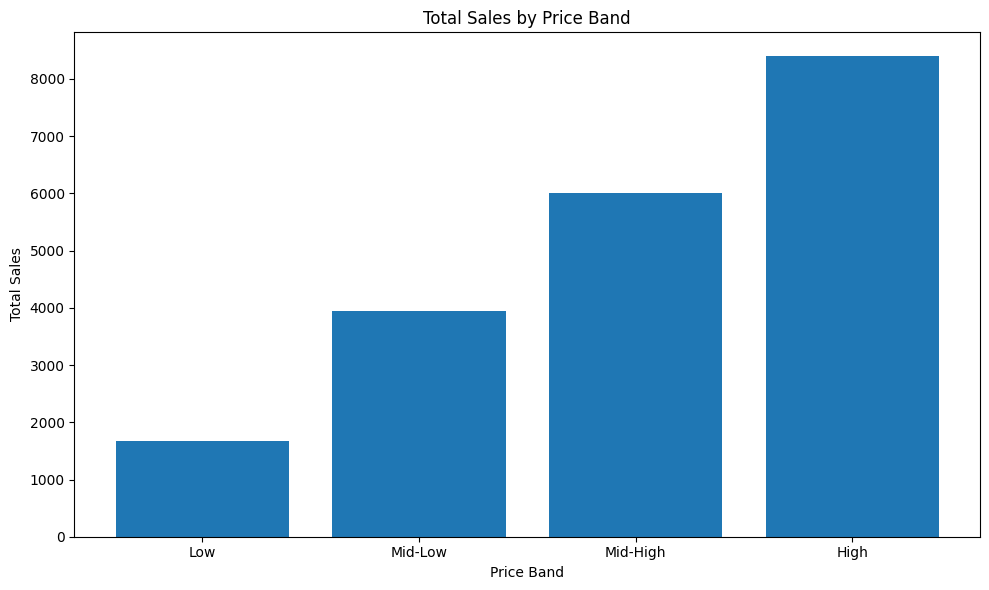

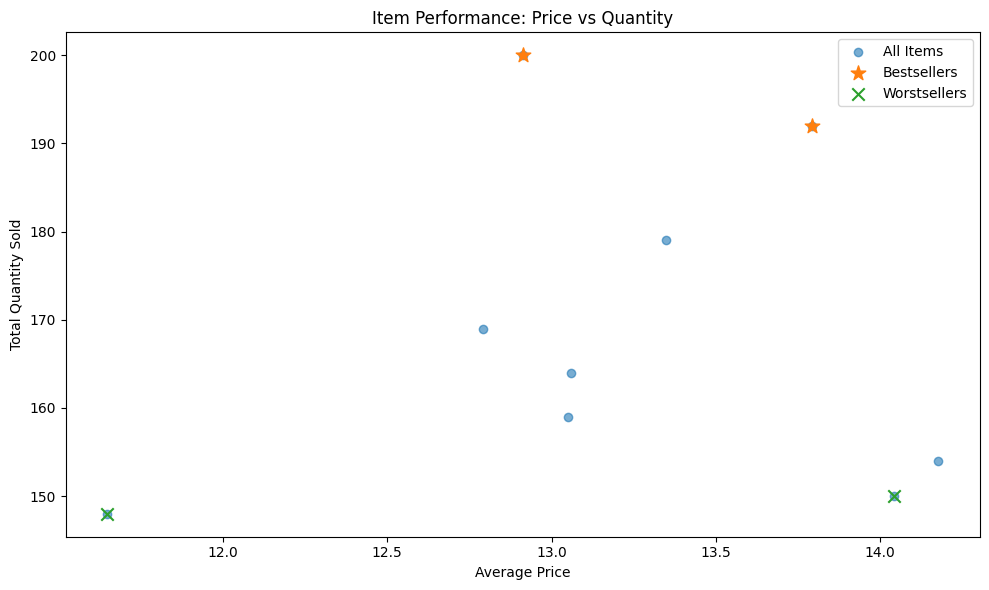

,price_band,total_qty,total_sales,avg_price,distinct_items
1,Low,372,1677.63,4.57256,9
3,Mid-Low,389,3936.83,10.09760,9
2,Mid-High,369,6013.64,16.31384,9
0,High,385,8395.04,21.80472,9


,Food Item,total_qty,total_sales,avg_price
0,Brownie,192,2570.19,13.793651
6,Pizza,200,2627.89,12.913235


,Food Item,total_qty,total_sales,avg_price
4,Ice Cream,148,1703.22,11.648269
8,Soup,150,2050.66,14.041800


In [7]:

# Price bands (quartiles)
q = df["Price"].quantile([0.25,0.5,0.75]).to_dict()
def band(p):
    if p <= q[0.25]: return "Low"
    if p <= q[0.5]:  return "Mid-Low"
    if p <= q[0.75]: return "Mid-High"
    return "High"

df["price_band"] = df["Price"].apply(band)

band_sales = (
    df.groupby("price_band", as_index=False)
      .agg(total_qty=("Quantity","sum"),
           total_sales=("line_total","sum"),
           avg_price=("Price","mean"),
           distinct_items=("Food Item","nunique"))
      .sort_values("avg_price")
)
band_sales.to_csv(f"{OUTDIR}/priceband_sales.csv", index=False)

item_perf = (
    df.groupby("Food Item", as_index=False)
      .agg(total_qty=("Quantity","sum"),
           total_sales=("line_total","sum"),
           avg_price=("Price","mean"))
)

qty_hi = item_perf["total_qty"].quantile(0.8)
sales_hi = item_perf["total_sales"].quantile(0.8)
qty_lo = item_perf["total_qty"].quantile(0.2)
sales_lo = item_perf["total_sales"].quantile(0.2)

bestsellers = item_perf[(item_perf["total_qty"]>=qty_hi) & (item_perf["total_sales"]>=sales_hi)]
worstsellers = item_perf[(item_perf["total_qty"]<=qty_lo) & (item_perf["total_sales"]<=sales_lo)]

bestsellers.to_csv(f"{OUTDIR}/bestsellers.csv", index=False)
worstsellers.to_csv(f"{OUTDIR}/worstsellers.csv", index=False)

# Plots
plt.figure()
plt.bar(band_sales["price_band"], band_sales["total_sales"])
plt.title("Total Sales by Price Band")
plt.xlabel("Price Band")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig(f"{OUTDIR}/priceband_sales.png")
plt.show()

plt.figure()
plt.scatter(item_perf["avg_price"], item_perf["total_qty"], alpha=0.6, label="All Items")
plt.scatter(bestsellers["avg_price"], bestsellers["total_qty"], marker="*", s=120, label="Bestsellers")
plt.scatter(worstsellers["avg_price"], worstsellers["total_qty"], marker="x", s=80, label="Worstsellers")
plt.title("Item Performance: Price vs Quantity")
plt.xlabel("Average Price")
plt.ylabel("Total Quantity Sold")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUTDIR}/item_perf_scatter.png")
plt.show()

display(band_sales)
display(bestsellers)
display(worstsellers)



**Reading the charts.** Low/Mid‑Low bands usually pull traffic; Mid‑High/High bands concentrate revenue.
I keep the **traffic drivers** as hooks (with combos) and verify whether **high‑priced anchors** deserve
special placement, chef notes, or limited‑time variants. Items deep in the *worstseller* zone are up for
**recipe refresh, portion tuning, or sunsetting**.



## G. Customer Segmentation (KMeans)

I standardize four features per customer — **#orders, total quantity, total spending, average ticket** —
and cluster them (KMeans, `k=4`) to get simple, actionable segments.


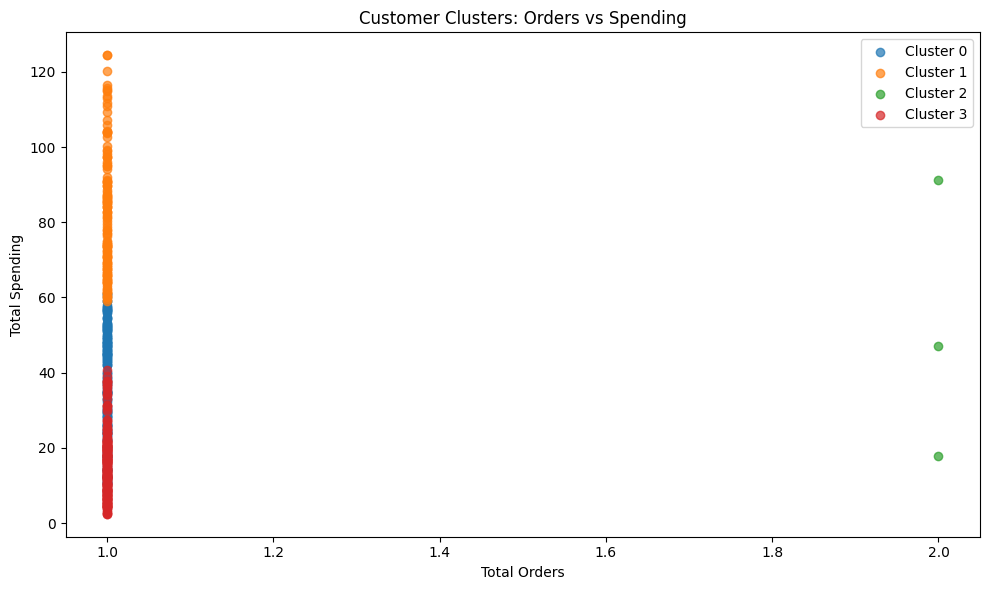

,cluster,customers,avg_orders,avg_qty,avg_spent,avg_ticket
0,0,164,1.0,3.847561,36.866341,36.866341
1,1,129,1.0,4.325581,82.535659,82.535659
2,2,3,2.0,6.000000,52.043333,26.021667
3,3,201,1.0,1.532338,15.790199,15.790199


In [8]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

cust_features = (
    df.groupby("Customer Name", as_index=False)
      .agg(
          total_orders=("Order ID", "nunique"),
          total_qty=("Quantity", "sum"),
          total_spent=("line_total", "sum"),
          avg_ticket=("line_total", "mean")
      )
)

X = cust_features[["total_orders","total_qty","total_spent","avg_ticket"]].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
cust_features["cluster"] = kmeans.fit_predict(X_scaled)

cust_features.to_csv(f"{OUTDIR}/customer_clusters.csv", index=False)

cluster_summary = (
    cust_features.groupby("cluster")
    .agg(customers=("Customer Name","count"),
         avg_orders=("total_orders","mean"),
         avg_qty=("total_qty","mean"),
         avg_spent=("total_spent","mean"),
         avg_ticket=("avg_ticket","mean"))
    .reset_index()
)
cluster_summary.to_csv(f"{OUTDIR}/cluster_summary.csv", index=False)

# Visualize (orders vs spending)
plt.figure(figsize=(10,6))
for cl in sorted(cust_features["cluster"].unique()):
    sub = cust_features[cust_features["cluster"]==cl]
    plt.scatter(sub["total_orders"], sub["total_spent"], label=f"Cluster {cl}", alpha=0.7)
plt.xlabel("Total Orders")
plt.ylabel("Total Spending")
plt.title("Customer Clusters: Orders vs Spending")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUTDIR}/customer_clusters_scatter.png")
plt.show()

display(cluster_summary)



**Interpreting segments.** Typical patterns include:  
- **One‑timers:** low orders, low spend — target with a welcome‑back coupon.  
- **Frugal regulars:** frequent but modest tickets — propose value sets to lift ARPU.  
- **Premium patrons:** medium/high frequency and high spend — give early access to seasonal or limited items.  

Programmatically, I map segments to **different offers and messages** instead of one‑size‑fits‑all promotions.



## Conclusion

This notebook compresses a restaurant’s operational intelligence into a single workflow: discover **what sells**,
**when it sells**, **who buys**, and **how profits emerge**. With a few charts and tables, I can adjust prep,
schedule staff to the peaks, promote the right payment channels, bundle popular pairs into **ready‑to‑order sets**,
and differentiate customer programs by segment. None of this requires exotic models; it requires **consistent
measurement** and **tight feedback loops** with the kitchen and the floor.

If you fork this for your own venue, consider adding margin columns (food cost %, prep time) and a simple daily
P&L to move from *revenue* to *profit* optimization. Then plug this into a dashboard app (e.g., Streamlit) so the
team can check tomorrow’s plan over pre‑shift coffee. Data becomes useful when it touches the line — prep list,
station layout, and menu highlights — not when it sits in a spreadsheet.
